[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L1/BA_L1_fee_share/BA_L1_fee_share.ipynb)

# BA_L1_fee_share: Miner Revenue: Block Subsidy and Fees

*Quantlet of Lecture 1, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Bitcoin miner revenue per day in USD from the block subsidy and from transaction fees (30-day means) and the share of fees in miner revenue, November 2014 to 8 October 2025, with the three halvings; with one day of revenue worked out step by step.

In [1]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [2]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [3]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

In [4]:
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 10, 'axes.titlesize': 10, 'lines.linewidth': 1.5})   # as in the slide charts


def load_onchain(name):
    # daily on-chain series, one column per coin, as numbers (missing values are NaN)
    return onchain(name).apply(pd.to_numeric, errors='coerce')


def slide_legend(fig, bottom, ncol=3):
    # one legend for the whole figure, under the plots, as in the slides
    fig.legend(loc='lower center', ncol=ncol, frameon=False, fontsize=8)
    fig.tight_layout(rect=(0, bottom, 1, 1))

## Data and method

Miner revenue per day, in USD, has two parts:

- **subsidy** = blocks per day $\times$ subsidy per block (BTC) $\times$ Bitcoin price, with blocks per day
  $= 1\,440/\text{mean block time (minutes)}$ and the subsidy halved on 9 July 2016, 11 May 2020 and 20 April 2024;
- **fees** = transactions per day $\times$ average fee per transaction (USD).

The price is the EODHD daily close; the other series are the on-chain files.

**How to read the chart.** Left: both parts of revenue, 30-day means, log scale. Right: fees as a share of revenue,
from 30-day sums. Dotted green lines mark the halvings.

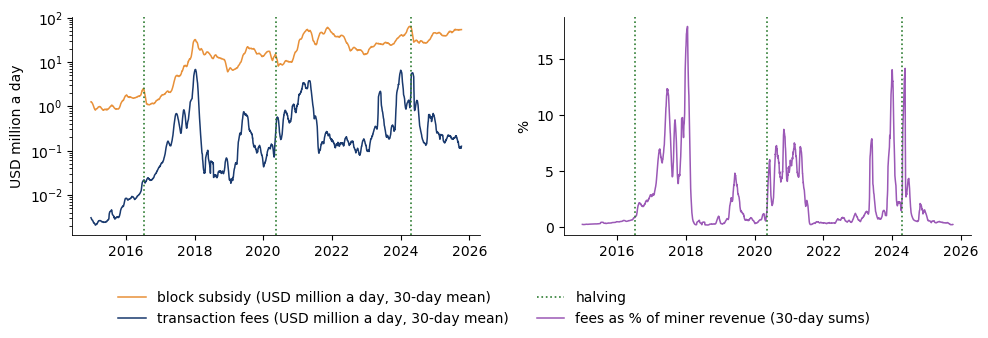

Fee share of miner revenue by year (%): 2014 0.2, 2015 0.4, 2016 1.3, 2017 10.4, 2018 2.5, 2019 1.6, 2020 3.6, 2021 2.8, 2022 0.5, 2023 4.0, 2024 3.0, 2025 0.4
Highest months: Dec 2017 15.7%, Dec 2023 13.5%, Jan 2018 11.9%
Last full month, September 2025: 0.22%
Last 30 days to 08 Oct 2025: miner revenue 53.7 USD million a day, fees 0.23% of it


In [5]:
# miner revenue per day, USD: block subsidy (blocks x subsidy x price) and fees (transactions x average fee)
btc_close = daily('BTC-USD.CC')
blocks_day = 1440 / load_onchain('blocktime')['BTC']
HALVINGS = ['2016-07-09', '2020-05-11', '2024-04-20']     # dates of the 2nd, 3rd and 4th halving
subsidy_btc = pd.Series(25.0, index=blocks_day.index)
for h_ in HALVINGS:
    subsidy_btc[subsidy_btc.index >= h_] /= 2
rev = pd.DataFrame({'subsidy': blocks_day * subsidy_btc * btc_close.reindex(blocks_day.index),
                    'fees': load_onchain('transaction')['BTC'] * load_onchain('transactionfee')['BTC']}).dropna()
rev30 = rev.rolling(30).sum().dropna()
fee_share = 100 * rev30['fees'] / rev30.sum(axis=1)

fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].plot(rev30.index, rev30['subsidy'] / 30 / 1e6, color=BTC, lw=1.1, label='block subsidy (USD million a day, 30-day mean)')
ax[0].plot(rev30.index, rev30['fees'] / 30 / 1e6, color=BLUE, lw=1.1, label='transaction fees (USD million a day, 30-day mean)')
ax[0].set_yscale('log'); ax[0].set_ylabel('USD million a day')
ax[1].plot(fee_share.index, fee_share, color=ETH, lw=1.1, label='fees as % of miner revenue (30-day sums)')
ax[1].set_ylabel('%')
for i, h_ in enumerate(HALVINGS):
    for a_ in ax:
        a_.axvline(pd.Timestamp(h_), color=GREEN, ls=':', lw=1.2, label=('halving' if i == 0 and a_ is ax[0] else None))
legend_below(fig, ncol=2, bottom=0.18)
save_fig(fig, 'ba_l1_fee_share')

fm = 100 * rev['fees'].resample('ME').sum() / rev.sum(axis=1).resample('ME').sum()
fy = 100 * rev['fees'].resample('YE').sum() / rev.sum(axis=1).resample('YE').sum()
print('Fee share of miner revenue by year (%):', ', '.join(f'{d.year} {v:.1f}' for d, v in fy.items()))
print('Highest months:', ', '.join(f'{d:%b %Y} {v:.1f}%' for d, v in fm.nlargest(3).items()))
print(f'Last full month, {fm.index[-2]:%B %Y}: {fm.iloc[-2]:.2f}%')
print(f'Last 30 days to {rev30.index[-1]:%d %b %Y}: miner revenue {rev30.iloc[-1].sum() / 30 / 1e6:.1f} USD million a day, '
      f'fees {fee_share.iloc[-1]:.2f}% of it')

One day of miner revenue, step by step, and the same day with the subsidy of the next halving.

In [6]:
# worked example: one day of miner revenue, the last day of the on-chain files
d_ = rev.index[-1]
bt_, n_tx, f_tx, px_ = load_onchain('blocktime').loc[d_, 'BTC'], load_onchain('transaction').loc[d_, 'BTC'], \
    load_onchain('transactionfee').loc[d_, 'BTC'], btc_close[d_]
print(f'{d_:%d %B %Y}: mean block time {bt_:.2f} minutes -> blocks = 1 440 / {bt_:.2f} = {1440 / bt_:.1f}')
print(f'Subsidy: {1440 / bt_:.1f} blocks x 3.125 BTC = {1440 / bt_ * 3.125:.1f} BTC; x {px_:,.0f} USD = {1440 / bt_ * 3.125 * px_ / 1e6:.1f} USD million')
print(f'Fees: {n_tx:,.0f} transactions x {f_tx:.3f} USD = {n_tx * f_tx / 1e6:.3f} USD million')
print(f'Fee share: {n_tx * f_tx / 1e6:.3f} / ({1440 / bt_ * 3.125 * px_ / 1e6:.1f} + {n_tx * f_tx / 1e6:.3f}) = '
      f'{100 * n_tx * f_tx / (n_tx * f_tx + 1440 / bt_ * 3.125 * px_):.2f}%')
print(f'Same day with the subsidy of the next halving (1.5625 BTC) and the same price and fees: '
      f'{100 * n_tx * f_tx / (n_tx * f_tx + 1440 / bt_ * 1.5625 * px_):.2f}%; miner revenue '
      f'{(1440 / bt_ * 1.5625 * px_ + n_tx * f_tx) / 1e6:.1f} USD million instead of {(1440 / bt_ * 3.125 * px_ + n_tx * f_tx) / 1e6:.1f}')

08 October 2025: mean block time 9.73 minutes -> blocks = 1 440 / 9.73 = 148.0
Subsidy: 148.0 blocks x 3.125 BTC = 462.5 BTC; x 123,355 USD = 57.1 USD million
Fees: 427,326 transactions x 0.350 USD = 0.150 USD million
Fee share: 0.150 / (57.1 + 0.150) = 0.26%
Same day with the subsidy of the next halving (1.5625 BTC) and the same price and fees: 0.52%; miner revenue 28.7 USD million instead of 57.2
